# Early Diabetes Risk Prediction Using Machine Learning

**What we will do**
1. Load and understand your dataset.
2. Check data quality and handle implausible zero measurements.
3. Explore patterns using simple charts.
4. Train three classification models.
5. Evaluate their performance fairly.
6. Test whether selecting fewer features changes performance.
7. Identify features the best model relies on.
8. Save tables and figures for the research paper.

**Dataset used:** Your uploaded `diabetes.csv` file.

**Important:** This dataset records diabetes status; it does not track when diabetes first developed. In the paper, describe this as *diabetes status/risk prediction on a public dataset*, not as proof that the model can detect diabetes before onset. This is an educational experiment, not a medical diagnostic tool.

### Before you start
- Keep `diabetes.csv` in the same folder as this notebook.
- Run the notebook from the first cell to the last cell.
- If packages are missing, run this in the VS Code terminal:  
  `python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter`


## Step 1 — Import the libraries

**What is each library for?**
- `pandas`: read and inspect the CSV file.
- `numpy`: numerical operations.
- `matplotlib` and `seaborn`: charts.
- `scikit-learn`: split data, train models, and evaluate predictions.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
OUTPUT_FOLDER = Path("outputs")
OUTPUT_FOLDER.mkdir(exist_ok=True)

print("Libraries imported successfully.")
print("Results will be saved in:", OUTPUT_FOLDER.resolve())


Libraries imported successfully.
Results will be saved in: /content/outputs


## Step 2 — Load your dataset

The CSV file must be named `diabetes.csv` and stored beside this notebook.

The target column is `Outcome`:
- `0` = diabetes was not recorded for that row
- `1` = diabetes was recorded for that row

The other eight columns are the input features used by the models.


In [2]:
file_path = Path("diabetes.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "diabetes.csv was not found. Put the CSV file in the same folder as this notebook."
    )

df = pd.read_csv(file_path)

print("Number of rows and columns:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names and data types:")
df.info()


Number of rows and columns: (768, 9)

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Step 3 — Understand the data

Check summary statistics, missing values, and the number of records in each target class.

**Why?** Before training a model, we need to understand what the dataset contains and whether any values need attention.


In [3]:
print("Summary statistics:")
display(df.describe().T)

print("\nMissing values in each column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nOutcome counts (0 = no recorded diabetes, 1 = recorded diabetes):")
display(df["Outcome"].value_counts().sort_index().to_frame("Number of records"))

print("\nOutcome percentages:")
display((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(1).to_frame("Percent"))


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values in each column:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Outcome counts (0 = no recorded diabetes, 1 = recorded diabetes):


,Number of records
Outcome,
0,500
1,268



Outcome percentages:


,Percent
Outcome,
0,65.1
1,34.9


## Step 4 — Clean implausible zero measurements

In this dataset, a value of `0` for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, or `BMI` is considered an implausible measurement and is treated as missing data (`NaN`).

We will **not** change zero in `Pregnancies`, because zero pregnancies is a valid value.

The missing measurements are imputed using the **median of their respective columns** through `SimpleImputer` inside each machine-learning pipeline.

The imputer learns the median from the training data only and applies it to the test data. This prevents data leakage and ensures fair model evaluation.

Median imputation is used because it is less sensitive to extreme values (outliers) than mean imputation.

In [4]:
df = df.copy()

columns_where_zero_means_missing = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("Zero values before cleaning:")
print((df[columns_where_zero_means_missing] == 0).sum().to_string())

# Convert implausible zeros to NaN
df[columns_where_zero_means_missing] = (
    df[columns_where_zero_means_missing].replace(0, np.nan)
)

print("\nMissing values after converting zeros:")
print(df.isna().sum().to_string())

print("\nDuplicate rows:", df.duplicated().sum())

Zero values before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11

Missing values after converting zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0

Duplicate rows: 0


## Step 5 — Explore the data with charts (EDA)

EDA means *Exploratory Data Analysis*. It helps us see the shape of the data before modelling.

The charts below are useful for your paper. Remember: a pattern or correlation does not prove that one variable causes diabetes.


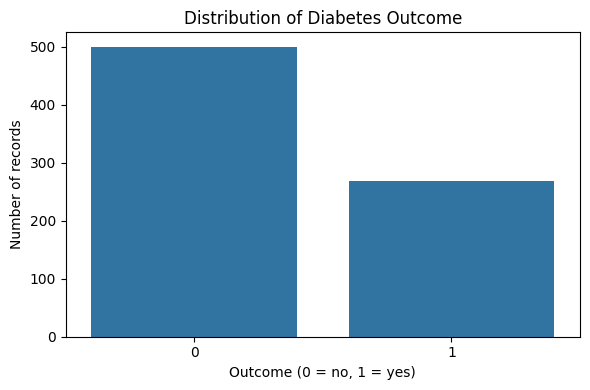

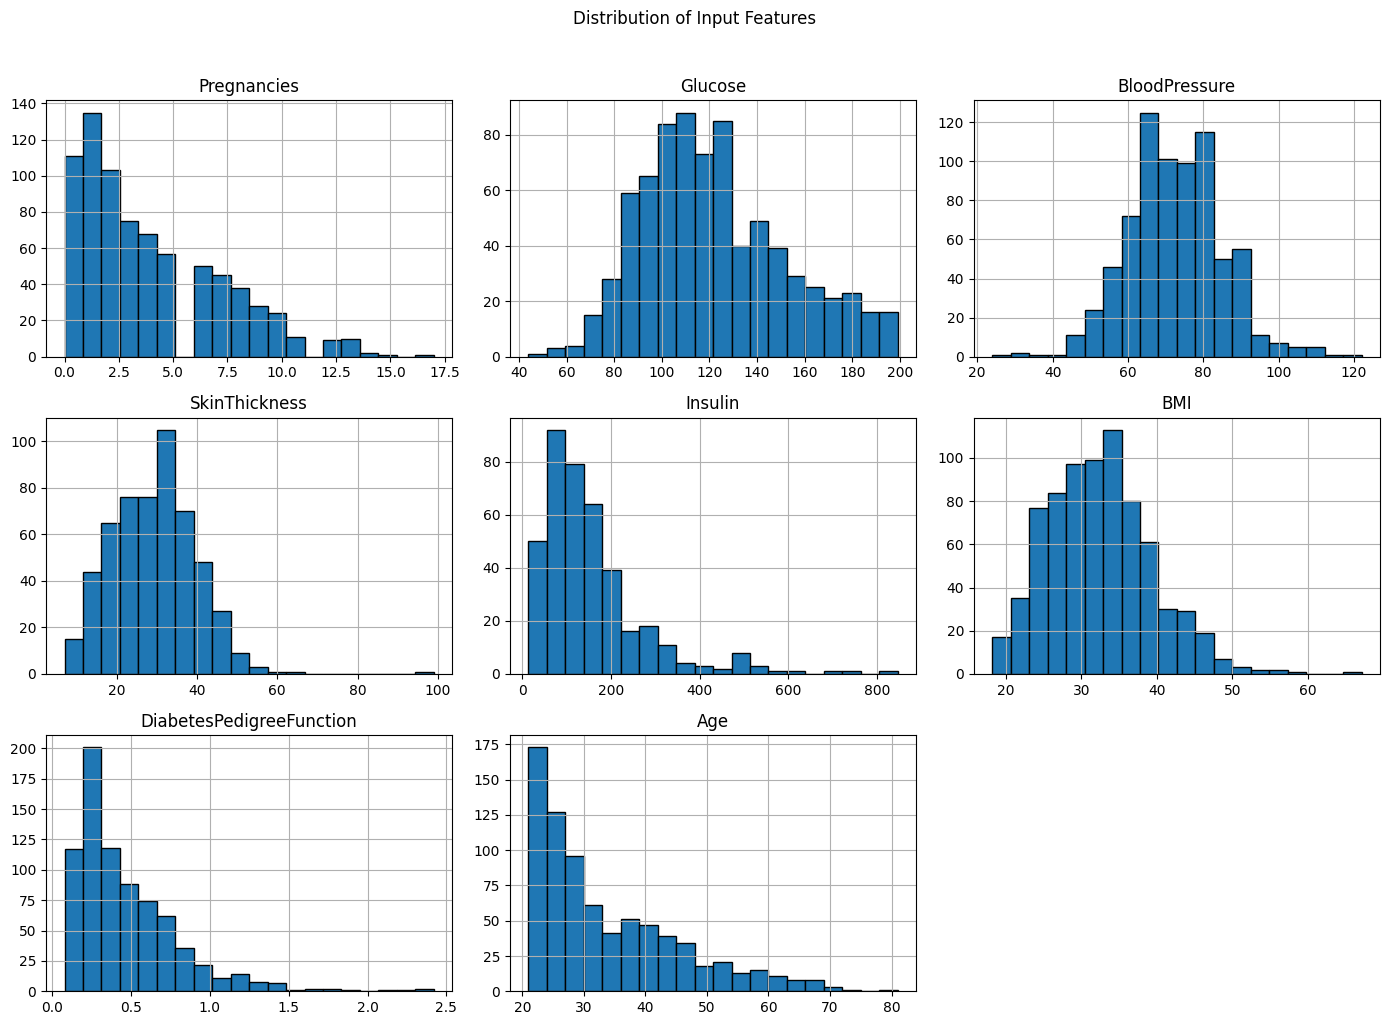

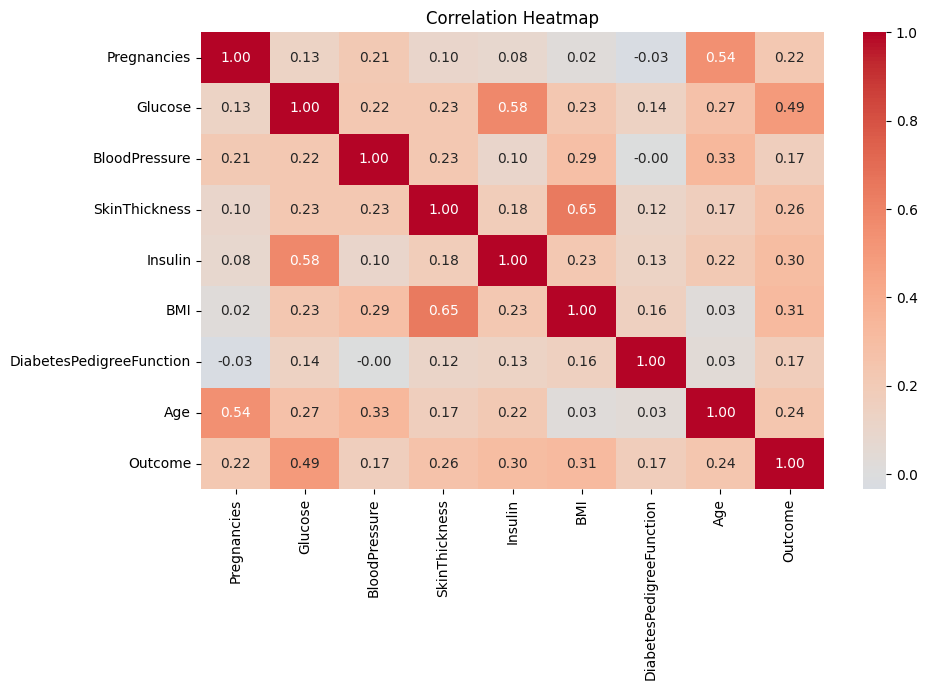

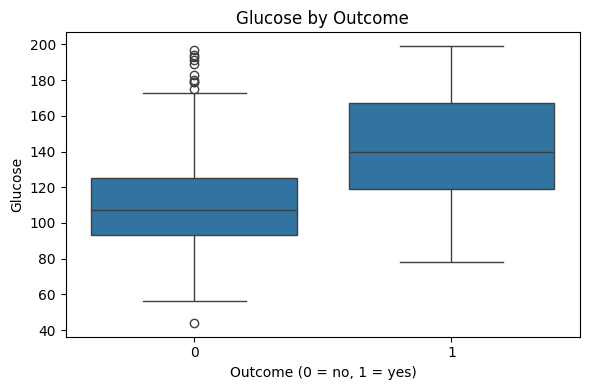

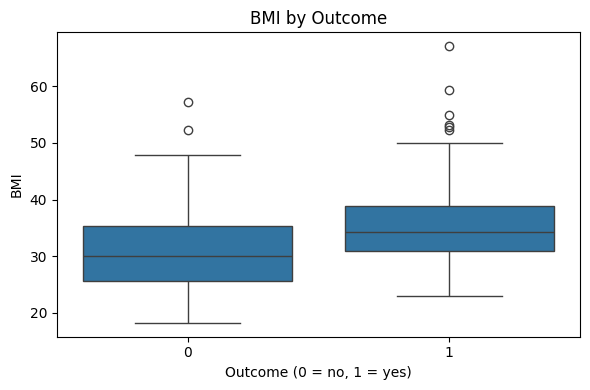

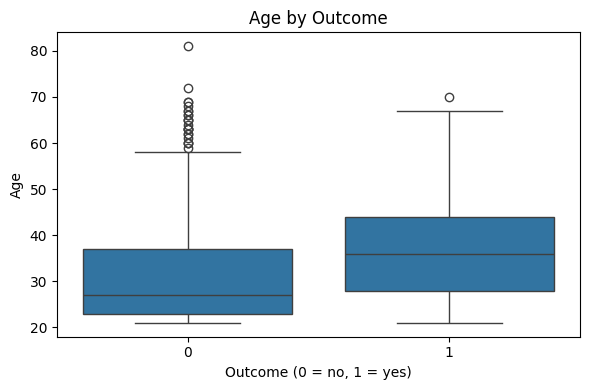

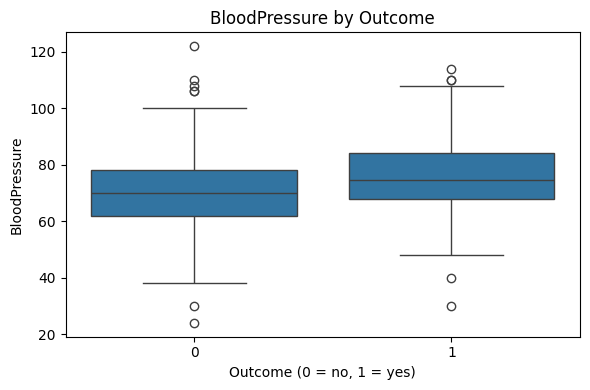

Charts saved in: /content/outputs


In [5]:
# Chart 1: How many rows are in each outcome class?
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = no, 1 = yes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "01_outcome_distribution.png", dpi=200)
plt.show()

# Chart 2: Distribution of each input feature
df.drop(columns="Outcome").hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Input Features", y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "02_feature_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 3: Correlations between numeric columns
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "03_correlation_heatmap.png", dpi=200)
plt.show()

# Chart 4: Compare a few features across outcome groups
for feature in ["Glucose", "BMI", "Age", "BloodPressure"]:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Outcome", y=feature)
    plt.title(f"{feature} by Outcome")
    plt.xlabel("Outcome (0 = no, 1 = yes)")
    plt.tight_layout()
    plt.savefig(OUTPUT_FOLDER / f"04_{feature.lower()}_by_outcome.png", dpi=200)
    plt.show()

print("Charts saved in:", OUTPUT_FOLDER.resolve())


## Step 6 — Separate the input features and target, then split the data

- `X` contains the eight input features.
- `y` contains the target (`Outcome`).
- We keep 20% of the data for final testing.
- `stratify=y` keeps the proportion of each outcome similar in training and test sets.
- The test set is held back until model evaluation.

**Avoid data leakage:** Missing-value imputation and scaling will be fitted inside each model pipeline using training data.


In [6]:
X = df.drop(columns="Outcome")
y = df["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training outcome-1 proportion:", round(y_train.mean(), 3))
print("Test outcome-1 proportion:", round(y_test.mean(), 3))


Training rows: 614
Test rows: 154
Training outcome-1 proportion: 0.349
Test outcome-1 proportion: 0.351


## Step 7 — Create three machine-learning models

We will compare:

1. **Logistic Regression:** a useful classification baseline.
2. **Decision Tree:** learns decision rules from the features.
3. **Random Forest:** combines multiple decision trees.

A pipeline combines preprocessing and the model, so the same steps are applied consistently. Logistic Regression uses feature scaling; tree models do not need scaling.


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models prepared:", ", ".join(models.keys()))


Models prepared: Logistic Regression, Decision Tree, Random Forest


## Step 8 — Train and evaluate the models

Each model learns from `X_train` and `y_train`. We then predict the outcomes for the unseen test set.

Metrics:
- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among predicted positives, how many were actual positives?
- **Recall:** among actual positives, how many did the model identify?
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** how well the model ranks positive cases above negative cases across thresholds.

For health-risk screening, do not judge the model by accuracy alone. Recall is important, but high recall may also produce more false positives.


In [8]:
baseline_rows = []
trained_models = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[model_name] = model

    # Predict the held-out test set
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    baseline_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("ROC-AUC", ascending=False)
display(baseline_results.round(3))

baseline_results.to_csv(OUTPUT_FOLDER / "01_baseline_model_results.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Random Forest,0.747,0.632,0.667,0.649,0.817
0,Logistic Regression,0.708,0.600,0.500,0.545,0.813
1,Decision Tree,0.792,0.696,0.722,0.709,0.801


## Step 9 — Hyperparameter tuning

Hyperparameter tuning helps us find better model configurations by testing different parameter combinations.

We will use `GridSearchCV` with five-fold stratified cross-validation to tune Logistic Regression, Decision Tree, and Random Forest.

We will optimize the F1-score to balance precision and recall while also recording accuracy and other evaluation metrics.

The original baseline models will remain unchanged so that we can compare their performance against the tuned models.

**Important:** The test dataset will not be used during hyperparameter tuning. It will only be used for the final evaluation of the tuned models.

In [9]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter search spaces
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "classifier__max_depth": [3, 4, 5, 7, None],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 5, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [5, 10, None],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__class_weight": [None, "balanced"]
    }
}

# Evaluate multiple metrics during cross-validation
tuning_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

tuned_models = {}
tuning_rows = []
tuned_test_rows = []

for model_name, model in models.items():

    print(f"\nTuning {model_name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[model_name],
        scoring=tuning_scoring,
        refit="f1",
        cv=StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    tuned_models[model_name] = best_model

    # Store best cross-validation results
    best_index = grid_search.best_index_

    tuning_rows.append({
        "Model": model_name,
        "CV Accuracy": grid_search.cv_results_["mean_test_accuracy"][best_index],
        "CV Precision": grid_search.cv_results_["mean_test_precision"][best_index],
        "CV Recall": grid_search.cv_results_["mean_test_recall"][best_index],
        "CV F1-score": grid_search.best_score_,
        "CV ROC-AUC": grid_search.cv_results_["mean_test_roc_auc"][best_index],
        "Best Parameters": grid_search.best_params_
    })

    # Final evaluation on untouched test data
    predictions = best_model.predict(X_test)
    probabilities = best_model.predict_proba(X_test)[:, 1]

    tuned_test_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# Display cross-validation tuning results
tuning_results = pd.DataFrame(tuning_rows)

print("\nBest Hyperparameter Configurations:")
print(tuning_results.to_string(index=False))

# Display final test results
tuned_results = pd.DataFrame(tuned_test_rows)

print("\nTuned Model Performance on Test Set:")
print(tuned_results.round(3).to_string(index=False))

# Save results
tuning_results.to_csv(
    OUTPUT_FOLDER / "08_hyperparameter_tuning_cv.csv",
    index=False
)

tuned_results.to_csv(
    OUTPUT_FOLDER / "09_tuned_model_results.csv",
    index=False
)


Tuning Logistic Regression...

Tuning Decision Tree...

Tuning Random Forest...

Best Hyperparameter Configurations:
              Model  CV Accuracy  CV Precision  CV Recall  CV F1-score  CV ROC-AUC                                                                                                                                                              Best Parameters
Logistic Regression     0.767106      0.651478   0.719823     0.682340    0.844994                                                                                                               {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
      Decision Tree     0.719872      0.572418   0.789701     0.662666    0.779412                                 {'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
      Random Forest     0.783393      0.671457   0.752381     0.707846    0.837648 {'classifier__class_weight': 'b

BASELINE VS TUNED MODEL COMPARISON
              Model  Accuracy_Baseline  Precision_Baseline  Recall_Baseline  F1-score_Baseline  ROC-AUC_Baseline  Accuracy_Tuned  Precision_Tuned  Recall_Tuned  F1-score_Tuned  ROC-AUC_Tuned  Accuracy_Change  Precision_Change  Recall_Change  F1-score_Change  ROC-AUC_Change
      Random Forest              0.747               0.632            0.667              0.649             0.817           0.734            0.597         0.741           0.661          0.820           -0.013            -0.035          0.074            0.013           0.003
Logistic Regression              0.708               0.600            0.500              0.545             0.813           0.708            0.571         0.667           0.615          0.810            0.000            -0.029          0.167            0.070          -0.003
      Decision Tree              0.792               0.696            0.722              0.709             0.801           0.727            0.6

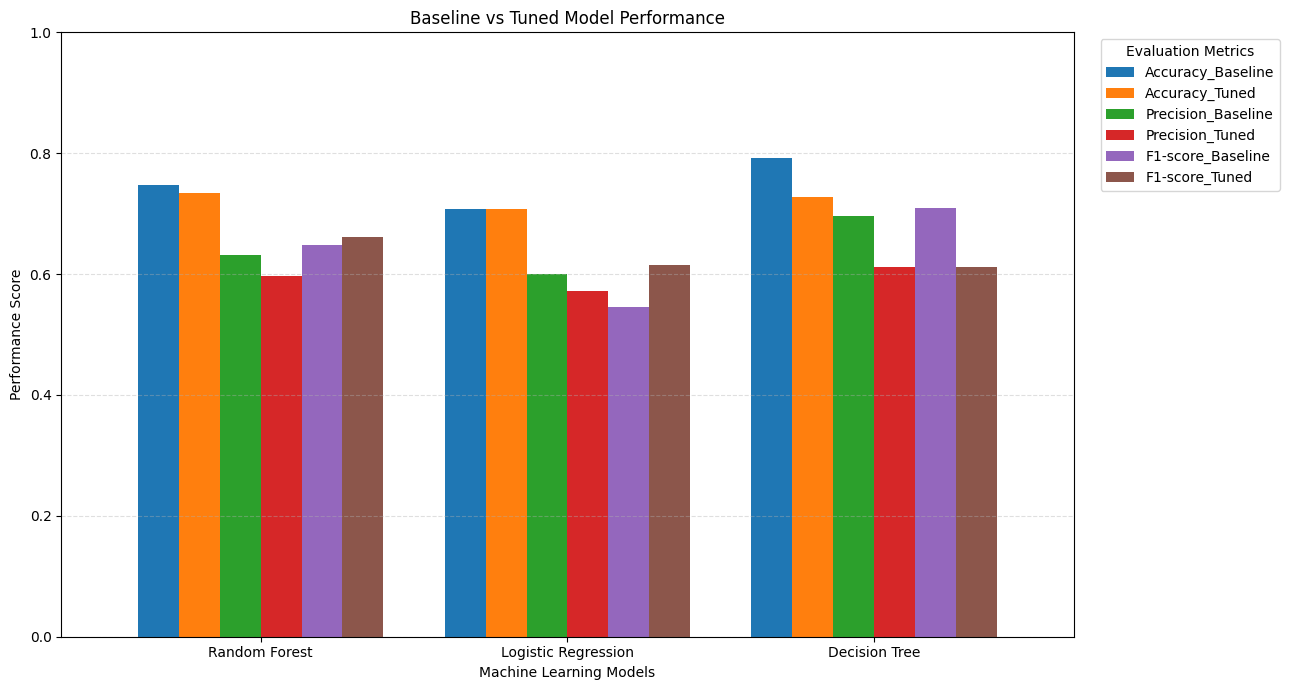

In [10]:
# Compare baseline and tuned model performance

comparison_results = baseline_results.merge(
    tuned_results,
    on="Model",
    suffixes=("_Baseline", "_Tuned")
)

# Calculate performance changes
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

for metric in metrics:
    comparison_results[f"{metric}_Change"] = (
        comparison_results[f"{metric}_Tuned"]
        - comparison_results[f"{metric}_Baseline"]
    )

print("BASELINE VS TUNED MODEL COMPARISON")
print(comparison_results.round(3).to_string(index=False))

# Save comparison
comparison_results.to_csv(
    OUTPUT_FOLDER / "10_baseline_vs_tuned_comparison.csv",
    index=False
)

# Visual comparison: Baseline vs Tuned models

comparison_plot = comparison_results.set_index("Model")[
    [
        "Accuracy_Baseline",
        "Accuracy_Tuned",
        "Precision_Baseline",
        "Precision_Tuned",
        "F1-score_Baseline",
        "F1-score_Tuned"
    ]
]

comparison_plot.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Baseline vs Tuned Model Performance")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    OUTPUT_FOLDER / "10_baseline_vs_tuned_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 10 — Look at errors and ROC curves

A confusion matrix shows:
- **True negatives:** correctly predicted outcome 0.
- **False positives:** predicted 1 when the recorded outcome is 0.
- **False negatives:** predicted 0 when the recorded outcome is 1.
- **True positives:** correctly predicted outcome 1.

These error types matter more than a single accuracy number. The ROC curve shows the trade-off between true-positive and false-positive rates at different thresholds.


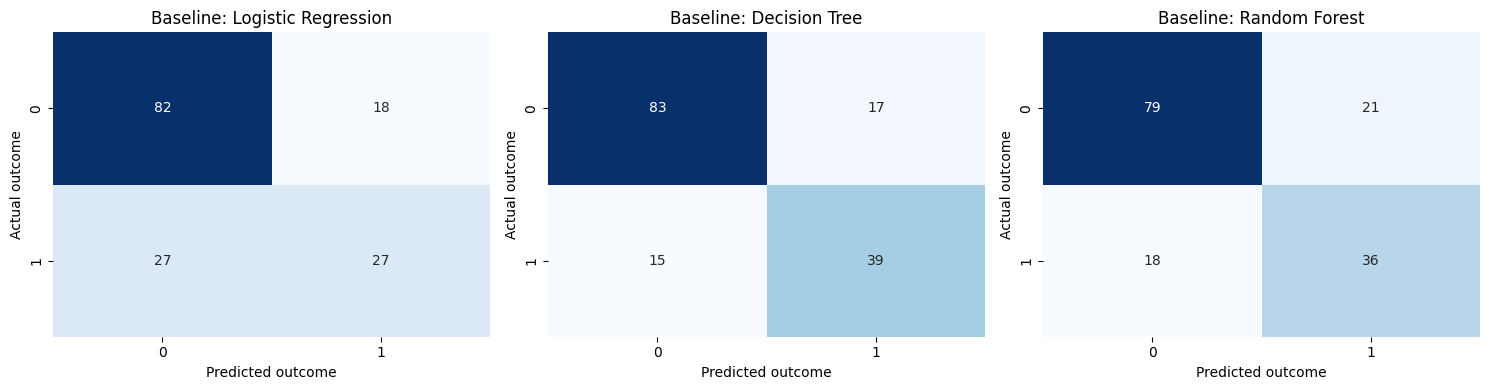

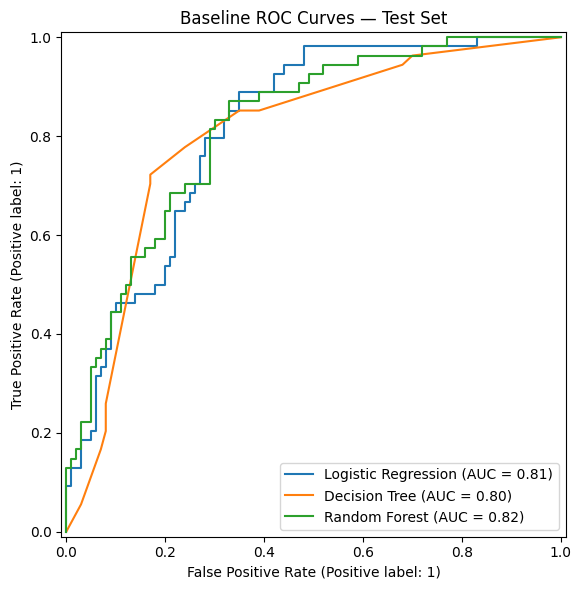

Highest test ROC-AUC in this split: Random Forest
              precision    recall  f1-score   support

           0       0.81      0.79      0.80       100
           1       0.63      0.67      0.65        54

    accuracy                           0.75       154
   macro avg       0.72      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



In [11]:
# Confusion matrices for all three models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, (model_name, model) in zip(axes, trained_models.items()):
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
    axis.set_title(f"Baseline: {model_name}")
    axis.set_xlabel("Predicted outcome")
    axis.set_ylabel("Actual outcome")

plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "05_confusion_matrices.png", dpi=200)
plt.show()

# ROC curves
fig, axis = plt.subplots(figsize=(7, 6))
for model_name, model in trained_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=model_name, ax=axis)

axis.set_title("Baseline ROC Curves — Test Set")
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "06_roc_curves.png", dpi=200)
plt.show()

# Detailed report for the model with the highest test ROC-AUC
best_model_name = baseline_results.iloc[0]["Model"]
print("Highest test ROC-AUC in this split:", best_model_name)
print(classification_report(
    y_test,
    trained_models[best_model_name].predict(X_test),
    zero_division=0
))


## Step 11 — Test feature selection

**Question:** Can we use fewer than eight features and retain similar predictive performance?

We will compare each baseline model with a version that selects the top five features using ANOVA F-scores (`SelectKBest`). This is a simple, reproducible feature-selection experiment.

The feature selector is inside the pipeline, so it is fitted only on training data. Five features is an experimental choice, not a claim that five is the ideal number.


In [12]:
import copy

selected_models = {}
selected_rows = []
selected_feature_rows = []

for model_name, original_pipeline in models.items():
    # Deep copy to ensure we do NOT modify the baseline estimators in trained_models
    copied_pipeline = copy.deepcopy(original_pipeline)

    new_steps = []
    for step_name, step in copied_pipeline.steps:
        if step_name == "classifier":
            new_steps.append(("feature_selection", SelectKBest(score_func=f_classif, k=5)))
        new_steps.append((step_name, step))

    selected_pipeline = Pipeline(new_steps)
    selected_pipeline.fit(X_train, y_train)
    selected_models[model_name] = selected_pipeline

    predictions = selected_pipeline.predict(X_test)
    probabilities = selected_pipeline.predict_proba(X_test)[:, 1]

    selected_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    selector = selected_pipeline.named_steps["feature_selection"]
    selected_feature_rows.append({
        "Model": model_name,
        "Selected features": ", ".join(X.columns[selector.get_support()].tolist())
    })

selected_results = pd.DataFrame(selected_rows)
feature_comparison = baseline_results.merge(
    selected_results,
    on="Model",
    suffixes=("_all_8_features", "_selected_5_features")
)

print("Performance comparison: all 8 features vs selected 5 features")
display(feature_comparison.round(3))
feature_comparison.to_csv(OUTPUT_FOLDER / "02_feature_selection_comparison.csv", index=False)

print("\nFeatures selected for each model:")
selected_features = pd.DataFrame(selected_feature_rows)
display(selected_features)
selected_features.to_csv(OUTPUT_FOLDER / "03_selected_features.csv", index=False)

Performance comparison: all 8 features vs selected 5 features


,Model,Accuracy_all_8_features,Precision_all_8_features,Recall_all_8_features,F1-score_all_8_features,ROC-AUC_all_8_features,Accuracy_selected_5_features,Precision_selected_5_features,Recall_selected_5_features,F1-score_selected_5_features,ROC-AUC_selected_5_features
0,Random Forest,0.747,0.632,0.667,0.649,0.817,0.753,0.621,0.759,0.683,0.819
1,Logistic Regression,0.708,0.600,0.500,0.545,0.813,0.721,0.617,0.537,0.574,0.787
2,Decision Tree,0.792,0.696,0.722,0.709,0.801,0.792,0.696,0.722,0.709,0.809



Features selected for each model:


,Model,Selected features
0,Logistic Regression,"Glucose, SkinThickness, Insulin, BMI, Age"
1,Decision Tree,"Glucose, SkinThickness, Insulin, BMI, Age"
2,Random Forest,"Glucose, SkinThickness, Insulin, BMI, Age"


## Step 12 — Understand which features the model relies on

We use **permutation importance** for the model with the highest test ROC-AUC. The method shuffles one feature at a time and measures how much the model's ROC-AUC changes.

A larger decrease suggests the model relied more on that feature for this dataset and test split. This does **not** prove that the feature causes diabetes. Correlated features can also share importance.


,Feature,Mean importance,Importance standard deviation
1,Glucose,0.1077,0.0264
5,BMI,0.0405,0.0168
7,Age,0.0240,0.0095
4,Insulin,0.0053,0.0068
6,DiabetesPedigreeFunction,0.0034,0.0079
0,Pregnancies,0.0033,0.0051
3,SkinThickness,-0.0006,0.0040
2,BloodPressure,-0.0026,0.0036


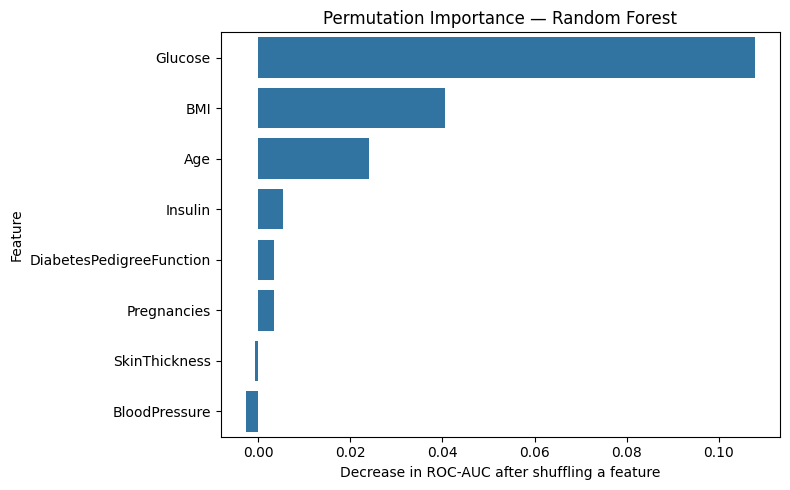

In [13]:
best_model = trained_models[best_model_name]

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=RANDOM_STATE
)

importance_results = pd.DataFrame({
    "Feature": X.columns,
    "Mean importance": importance.importances_mean,
    "Importance standard deviation": importance.importances_std
}).sort_values("Mean importance", ascending=False)

display(importance_results.round(4))
importance_results.to_csv(OUTPUT_FOLDER / "04_permutation_importance.csv", index=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_results, x="Mean importance", y="Feature")
plt.title(f"Permutation Importance — {best_model_name}")
plt.xlabel("Decrease in ROC-AUC after shuffling a feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "07_permutation_importance.png", dpi=200)
plt.show()

## Step 13 — Cross-validation check

A single train/test split can give an unstable estimate, especially with a small dataset. We use five-fold stratified cross-validation on the **training set** to check how model scores vary across folds.

The final test set remains separate. Cross-validation is a stability check, not a guarantee that the model will work well on a different population.


In [14]:
cross_validator = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cross_validator,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    row = {"Model": model_name}
    for metric in scoring_metrics:
        row[f"{metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(3))
cv_results.to_csv(OUTPUT_FOLDER / "05_cross_validation_results.csv", index=False)


,Model,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,roc_auc mean,roc_auc std
0,Logistic Regression,0.788,0.019,0.764,0.060,0.575,0.023,0.655,0.024,0.843,0.019
1,Decision Tree,0.725,0.048,0.638,0.096,0.542,0.036,0.581,0.039,0.778,0.047
2,Random Forest,0.770,0.019,0.665,0.039,0.696,0.027,0.679,0.018,0.836,0.022


## Step 14 — Save a short summary and check your outputs

All tables and figures are saved in `outputs/`. Use the actual numbers from your output files when writing the Results section tomorrow.

**Do not claim a model is best simply because it has the highest accuracy.** State which metric you prioritized and report the other metrics too. Avoid claiming that feature selection improves performance unless your results show that.


In [15]:
import json

summary = {
    "dataset": str(file_path),
    "rows": int(df.shape[0]),
    "input_features": int(X.shape[1]),
    "target_column": "Outcome",
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "best_baseline_model_by_test_roc_auc": str(best_model_name),
    "best_test_roc_auc": float(baseline_results.iloc[0]["ROC-AUC"]),
    "note": "Educational experiment only; not a clinically validated diagnostic system."
}

with open(OUTPUT_FOLDER / "experiment_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("\nOutput files:")
for output_file in sorted(OUTPUT_FOLDER.iterdir()):
    print(" -", output_file.name)


Output files:
 - 01_baseline_model_results.csv
 - 01_outcome_distribution.png
 - 02_feature_distributions.png
 - 02_feature_selection_comparison.csv
 - 03_correlation_heatmap.png
 - 03_selected_features.csv
 - 04_age_by_outcome.png
 - 04_bloodpressure_by_outcome.png
 - 04_bmi_by_outcome.png
 - 04_glucose_by_outcome.png
 - 04_permutation_importance.csv
 - 05_confusion_matrices.png
 - 05_cross_validation_results.csv
 - 06_roc_curves.png
 - 07_permutation_importance.png
 - 08_hyperparameter_tuning_cv.csv
 - 09_tuned_model_results.csv
 - 10_baseline_vs_tuned_comparison.csv
 - 10_baseline_vs_tuned_comparison.png
 - experiment_summary.json
